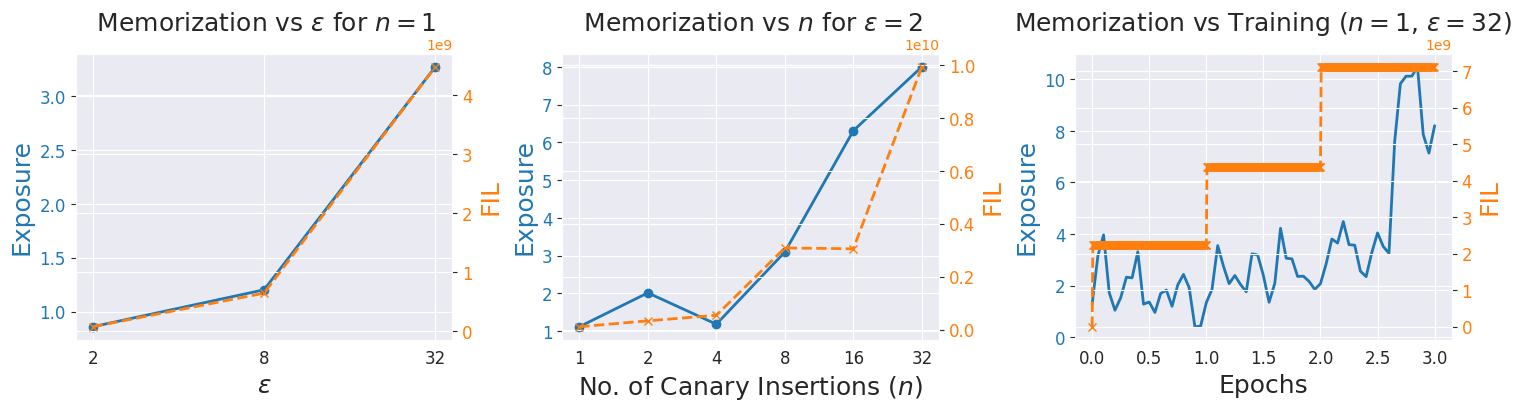

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
import re
from matplotlib.lines import Line2D
from matplotlib.ticker import FixedLocator, FixedFormatter


sns.set_style('darkgrid')
plt.rcParams.update({
    'lines.linewidth': 2,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'axes.labelsize': 14,
    'legend.fontsize': 12,
    'axes.titlesize': 16,
})
exp_df_1 = pd.read_csv('/home/ishitak/ssh/synthAI/csvs/run-03_expt-01&3_Exp.csv')
fil_df_1 = pd.read_csv('/home/ishitak/ssh/synthAI/csvs/run-03_expt-01&3_FIL.csv')
exp_df_2 = pd.read_csv('/home/ishitak/ssh/synthAI/csvs/run-03_expt-02_Exp.csv')
fil_df_2 = pd.read_csv('/home/ishitak/ssh/synthAI/csvs/run-03_expt-02_FIL.csv')
def exp_col(eps):
    return f'Num=1,epsilon={eps}_lr=0.0001 - Exposure'

def fil_col(eps):
    return f'FIL Num=1,epsilon={eps} - FIL'

epsilons = sorted([
    int(re.search(r'epsilon=(\d+)', c).group(1))
    for c in exp_df_1.columns
    if re.search(r'epsilon=(\d+)', c) and c.endswith('Exposure')
    and not c.endswith('__MIN') and not c.endswith('__MAX')
])

BLUE   = 'C0'
ORANGE = 'C1'

def add_twin_fil(ax, x, y):
    ax2 = ax.twinx()
    ax2.plot(x, y, color=ORANGE, linestyle='--', marker='x', linewidth=2)
    ax2.set_ylabel('FIL', color=ORANGE, fontsize=18)
    ax2.tick_params(axis='y', labelcolor=ORANGE, labelsize=12)
    ax2.yaxis.offsetText.set_fontsize(10)
    return ax2

fig, axs = plt.subplots(1, 3, figsize=(15,4), constrained_layout=True)

ax1 = axs[0]

exp_vals_eps = [exp_df_1[exp_col(e)].mean() for e in epsilons]
fil_vals_eps = [fil_df_1[fil_col(e)].mean() for e in epsilons]

ax1.plot(epsilons, exp_vals_eps, color=BLUE, marker='o')
ax1.set_xlabel(r'$\varepsilon$', fontsize=18)
ax1.set_ylabel('Exposure', color=BLUE, fontsize=18)
ax1.tick_params(axis='y', labelcolor=BLUE)
ax1.set_title(r'     Memorization vs $\varepsilon$ for $n = 1$     ', fontsize=18)
ax1.set_xscale('log', base=2)
ax1.xaxis.set_major_locator(FixedLocator(epsilons))
ax1.xaxis.set_major_formatter(FixedFormatter(['2', '8', '32']))

ax1.set_xticks(epsilons)
ax1.set_xticklabels([str(e) for e in epsilons])  
ax1b = add_twin_fil(ax1, epsilons, fil_vals_eps)
ax1b.set_xscale('log', base=2)
ax1b.xaxis.set_major_locator(FixedLocator(epsilons))
ax1b.xaxis.set_major_formatter(FixedFormatter(['2', '8', '32']))

ax2 = axs[1]

exp_n_xcol = 'Number of insertions of Canary'
exp_n_ycol = 'Exposure vs Number of insertions of Canary - Exposure'
fil_n_xcol = 'Number of insertions'
fil_n_ycol = 'FIL, epsilon=2 - FIL'

n_vals      = exp_df_2[exp_n_xcol].values
n_positions = list(range(len(n_vals)))
n_labels    = [str(int(v)) for v in n_vals]

ax2.plot(n_positions, exp_df_2[exp_n_ycol].values, color=BLUE, marker='o')
ax2.set_xlabel('No. of Canary Insertions ($n$)', fontsize=18)
ax2.set_ylabel('Exposure', color=BLUE, fontsize=18)
ax2.tick_params(axis='y', labelcolor=BLUE)
ax2.set_title(r'    Memorization vs $n$ for $\varepsilon = 2$    ', fontsize=18)
ax2.set_xticks(n_positions)
ax2.set_xticklabels(n_labels)

fil_n_vals    = fil_df_2[fil_n_xcol].values
fil_positions = [n_labels.index(str(int(v))) for v in fil_n_vals if str(int(v)) in n_labels]
fil_y_vals    = fil_df_2[fil_n_ycol].values[:len(fil_positions)]

ax2b = add_twin_fil(ax2, fil_positions, fil_y_vals)
ax2b.set_xticks(n_positions)

fil_generated = (
    [0] +
    [2231369728] * 160 +
    [4362076160] * 160 +
    [7113539584] * 159
)

ax3 = axs[2]
eps_train = 32

x_exp = exp_df_1['Step']/160

ax3.plot(x_exp, exp_df_1[exp_col(eps_train)], color=BLUE)
ax3.set_xlabel('Epochs', fontsize=18)
ax3.set_ylabel('Exposure', color=BLUE, fontsize=18)
ax3.tick_params(axis='y', labelcolor=BLUE)
ax3.set_title(r'Memorization vs Training ($n = 1$, $\varepsilon = 32$)', fontsize=18)
ax3.xaxis.set_major_locator(ticker.MaxNLocator(nbins=5))

ax3b = add_twin_fil(ax3, [i / 160 for i in range(0, 480)], fil_generated)
ax3.set_xticks([0, 0.5, 1, 1.5, 2, 2.5, 3])
ax3b.set_xticks([0, 0.5, 1, 1.5, 2, 2.5, 3])

plt.savefig('/home/ishitak/ssh/synthAI/Plots_saved/run-03_Qwen.pdf', format='pdf', bbox_inches='tight', dpi=300)
plt.show()

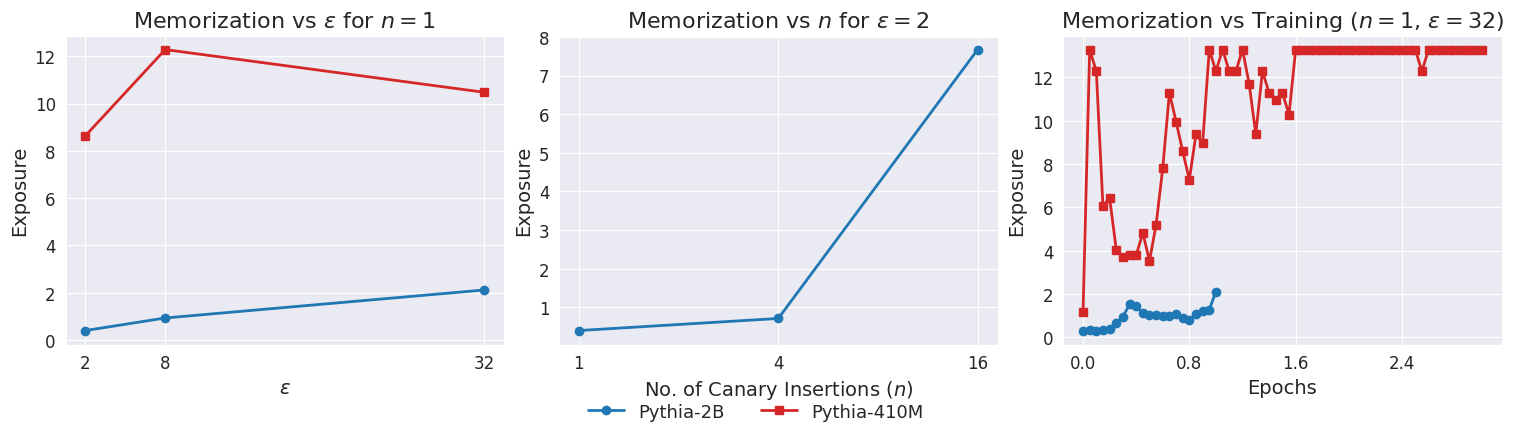

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
import re
from matplotlib.lines import Line2D

sns.set_style('darkgrid')
plt.rcParams.update({
    'lines.linewidth': 2,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'axes.labelsize': 14,
    'legend.fontsize': 12,
    'axes.titlesize': 16,
})

exp_df        = pd.read_csv('/home/ishitak/ssh/post-review/csvs/run-04_Exp_Pythia2b.csv')
df_410m       = pd.read_csv('/home/ishitak/ssh/post-review/csvs/run-02_Exp_Pythia410m_n=1.csv')
df_410m_train = pd.read_csv('/home/ishitak/ssh/post-review/csvs/run-02_Exp_Pythia410m_n=1,e=32.csv')

col_410m_train = [c for c in df_410m_train.columns if c.endswith('Exposure')][0]
def exp_col(num, eps):
    return f'Num={num},epsilon={eps}_lr=5e-05 - Exposure'

def exp_col_410m(num, eps):
    return f'Num={num},epsilon={eps} - Exposure'

ycols    = [col for col in exp_df.columns if col.endswith('Exposure')]
combos   = [(int(re.search(r'Num=(\d+)', c).group(1)),
             int(re.search(r'epsilon=(\d+)', c).group(1))) for c in ycols]
epsilons = sorted(set(e for _, e in combos))
nums     = sorted(set(n for n, _ in combos))

epsilons_410m = sorted(set(int(re.search(r'epsilon=(\d+)', c).group(1))
                           for c in df_410m.columns if c.endswith('Exposure')))

fig, axs = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)

ax1 = axs[0]
n_fixed = 1

exp_vals_eps_2b   = [exp_df[exp_col(n_fixed, e)].iloc[-1] for e in epsilons]
exp_vals_eps_410m = [df_410m[exp_col_410m(n_fixed, e)].iloc[-1] for e in epsilons_410m]

ax1.plot(epsilons,      exp_vals_eps_2b,   color='C0', marker='o')
ax1.plot(epsilons_410m, exp_vals_eps_410m, color='C3', marker='s')
ax1.set_xlabel(r'$\varepsilon$', fontsize=14)
ax1.set_ylabel('Exposure', fontsize=14)
ax1.set_title(r'Memorization vs $\varepsilon$ for $n = 1$', fontsize=16)
ax1.set_xticks(epsilons)

ax2 = axs[1]
eps_fixed = 2

positions  = list(range(len(nums)))
labels     = [str(n) for n in nums]
exp_vals_n = [exp_df[exp_col(n, eps_fixed)].iloc[-1] for n in nums]

ax2.plot(positions, exp_vals_n, color='C0', marker='o')
ax2.set_xlabel('No. of Canary Insertions ($n$)', fontsize=14)
ax2.set_ylabel('Exposure', fontsize=14)
ax2.set_title(r'Memorization vs $n$ for $\varepsilon = 2$', fontsize=16)
ax2.set_xticks(positions)
ax2.set_xticklabels(labels)

ax3 = axs[2]
n_train, eps_train = 1, 32

exp_series = exp_df[exp_col(n_train, eps_train)]
x_exp      = exp_df['Step'] / 160 if 'Step' in exp_df.columns else exp_df.index

x_410m     = df_410m_train['Step'] / 160 if 'Step' in df_410m_train.columns else df_410m_train.index

ax3.plot(x_exp,   exp_series,                        color='C0', marker='o')
ax3.plot(x_410m,  df_410m_train[col_410m_train],     color='C3', marker='s')
ax3.set_xlabel('Epochs', fontsize=14)
ax3.set_ylabel('Exposure', fontsize=14)
ax3.set_title(r'Memorization vs Training ($n = 1$, $\varepsilon = 32$)', fontsize=16)
ax3.xaxis.set_major_locator(ticker.MaxNLocator(nbins=5))

legend_handles = [
    Line2D([0], [0], color='C0', marker='o', linewidth=2, label='Pythia-2B'),
    Line2D([0], [0], color='C3', marker='s', linewidth=2, label='Pythia-410M'),
]
fig.legend(handles=legend_handles, loc='lower center',
           ncol=2, fontsize=13, frameon=False, bbox_to_anchor=(0.5, -0.08))

plt.savefig('/home/ishitak/ssh/post-review/plots_saved/run-04_pythia2b.pdf',
            format='pdf', bbox_inches='tight', dpi=300)
plt.show()

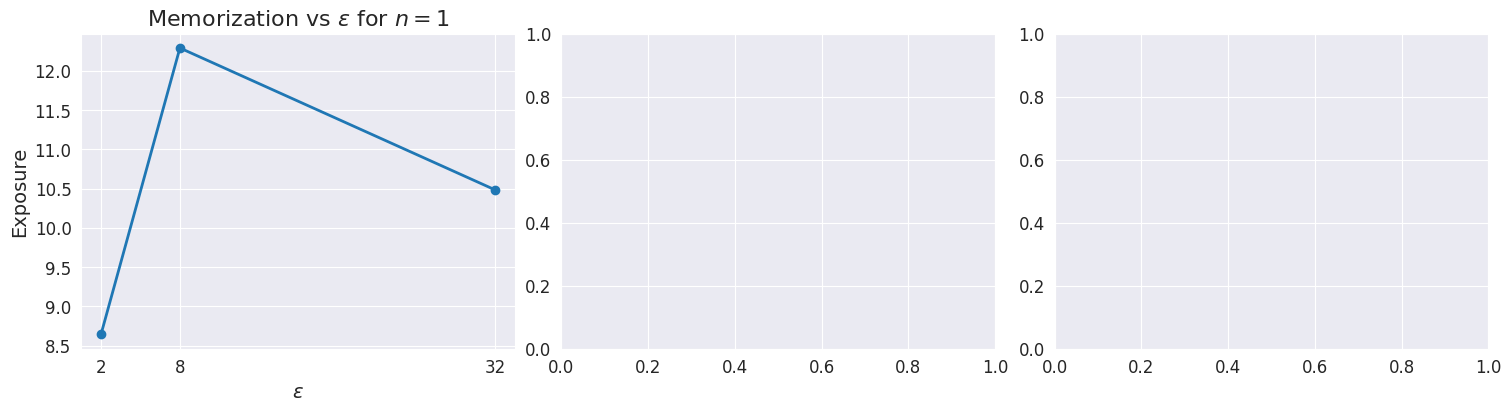

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
import re
from matplotlib.lines import Line2D

sns.set_style('darkgrid')
plt.rcParams.update({
    'lines.linewidth': 2,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'axes.labelsize': 14,
    'legend.fontsize': 12,
    'axes.titlesize': 16,
})

exp_df = pd.read_csv('/home/ishitak/ssh/post-review/csvs/run-02_Exp_Pythia410m_n=1.csv')

def exp_col(num, eps):
    return f'Num={num},epsilon={eps} - Exposure'  # adjust if needed

ycols    = [col for col in exp_df.columns if col.endswith('Exposure')]
combos   = [(int(re.search(r'Num=(\d+)', c).group(1)),
             int(re.search(r'epsilon=(\d+)', c).group(1))) for c in ycols]
epsilons = sorted(set(e for _, e in combos))
nums     = sorted(set(n for n, _ in combos))

BLUE = 'C0'

fig, axs = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)

ax1 = axs[0]
n_fixed = 1

exp_vals_eps = [exp_df[exp_col(n_fixed, e)].iloc[-1] for e in epsilons]

ax1.plot(epsilons, exp_vals_eps, color=BLUE, marker='o')
ax1.set_xlabel(r'$\varepsilon$', fontsize=14)
ax1.set_ylabel('Exposure', fontsize=14)
ax1.set_title(r'Memorization vs $\varepsilon$ for $n = 1$', fontsize=16)
ax1.set_xticks(epsilons)
plt.savefig('/home/ishitak/ssh/post-review/plots_saved/run-04_pythia2b.pdf', format='pdf', bbox_inches='tight', dpi=300)
plt.show()